**Library mapping used in this conversion:**

| R | Python |
|---|---|
| `tseries::get.hist.quote()` | `yfinance.download()` |
| `tseries::garch()` | `arch.arch_model()` |
| `stats::lm()` | `statsmodels.api.OLS()` |
| `qnorm`, `qt`, `quantile` | `scipy.stats.norm.ppf`, `scipy.stats.t.ppf`, `numpy.quantile` |
| `plot()` / `lines()` / `abline()` | `matplotlib` |

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from arch import arch_model
import statsmodels.api as sm
import yfinance as yf

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = False


# Volatility Risk & the GARCH(1,1) Model

In [2]:
# R: get.hist.quote(instrument = "^VIX", start="2015-01-01", end=Sys.Date(), quote="AdjClose", provider="yahoo")
start_date = "2015-01-01"
end_date = None  # None -> up to today, mirrors R's Sys.Date()

vix = yf.download("^VIX", start=start_date, end=end_date, auto_adjust=False)["Adj Close"].squeeze()
spy = yf.download("SPY", start=start_date, end=end_date, auto_adjust=False)["Adj Close"].squeeze()

print(f"VIX:  {vix.index[0].date()}  to  {vix.index[-1].date()}   ({len(vix)} obs)")
print(f"SPY:  {spy.index[0].date()}  to  {spy.index[-1].date()}   ({len(spy)} obs)")


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

VIX:  2015-01-02  to  2026-06-19   (2884 obs)
SPY:  2015-01-02  to  2026-06-18   (2882 obs)


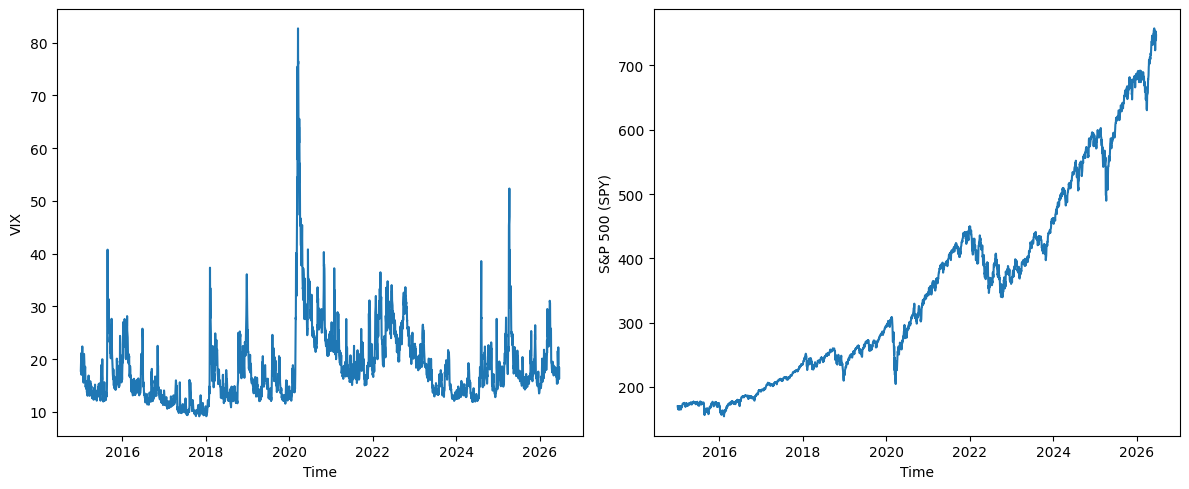

In [3]:
# R: par(mfrow=c(1,2)); plot(ts(VIX$AdjClose), ylab="VIX"); plot(ts(SnP.500$AdjClose), ylab="S&P 500")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(vix.index, vix.values)
axes[0].set_ylabel("VIX")
axes[0].set_xlabel("Time")

axes[1].plot(spy.index, spy.values)
axes[1].set_ylabel("S&P 500 (SPY)")
axes[1].set_xlabel("Time")

plt.tight_layout()
plt.show()


In [4]:
# R: ln_rt <- as.numeric(diff(log(SnP.500)))
ln_rt = np.log(spy).diff().dropna()
ln_rt.tail()


Date
2026-06-12    0.005394
2026-06-15    0.017480
2026-06-16   -0.005979
2026-06-17   -0.012566
2026-06-18    0.010343
Name: SPY, dtype: float64

In [5]:
# R: fit.garch <- garch(ln_rt, order=c(1,1))
# arch_model fits more reliably on a percentage scale, so we work with returns*100
# and rescale the fitted conditional volatility back down afterwards.
am = arch_model(ln_rt * 100, mean="Zero", vol="GARCH", p=1, q=1, dist="normal")
fit_garch = am.fit(disp="off")
print(fit_garch.summary())


                       Zero Mean - GARCH Model Results                        
Dep. Variable:                    SPY   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3736.05
Distribution:                  Normal   AIC:                           7478.09
Method:            Maximum Likelihood   BIC:                           7495.99
                                        No. Observations:                 2881
Date:                Sun, Jun 21 2026   Df Residuals:                     2881
Time:                        09:24:56   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega          0.0399  1.027e-02      3.881  1.042e-04 [1.

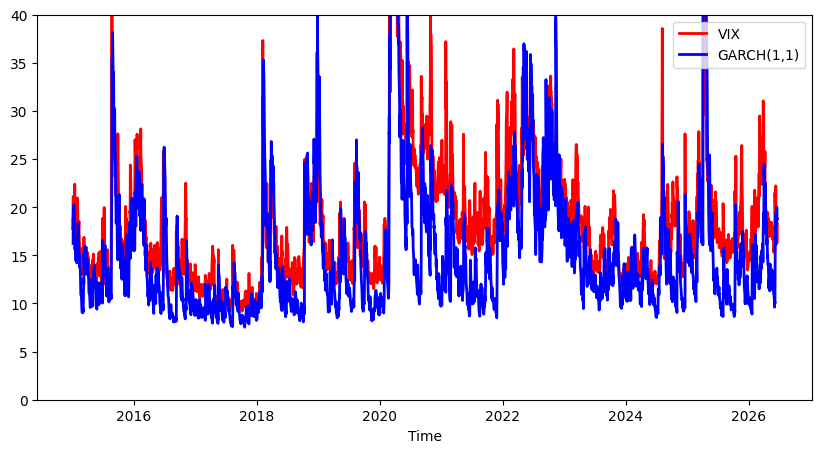

In [6]:
# R: sigma_hat <- fit.garch$fitted.values[,"sigt"]; vol_hat <- sigma_hat*sqrt(252)*100
sigma_hat = fit_garch.conditional_volatility / 100   # back to raw (decimal) return units
vol_hat = sigma_hat * np.sqrt(252) * 100              # annualised, in % -- directly comparable to VIX

# R: plot(ts(VIX$AdjClose), col="red", ...); lines(vol_hat, col="blue", ...); legend(...)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(vix.index, vix.values, color="red", linewidth=2, label="VIX")
ax.plot(vol_hat.index, vol_hat.values, color="blue", linewidth=2, label="GARCH(1,1)")
ax.set_ylim(0, 40)
ax.set_xlabel("Time")
ax.legend(loc="upper right")
plt.show()


## Value at Risk (VaR)


In [7]:
# R: vol <- sd(ln_rt); rbar <- mean(ln_rt)
vol = ln_rt.std()
rbar = ln_rt.mean()

# R: n <- length(SnP.500); unit <- 1000; Value <- SnP.500[n]
unit = 1000                     # number of units of SPY held
value = float(spy.iloc[-1])     # current price of SPY
value_p = value * unit          # value of the portfolio
hp = 1                          # 1-day holding period
a = 0.95                        # 95% confidence (5% VaR)

print(f"Current SPY price: {value:.2f}")
print(f"Portfolio value (1000 units): {value_p:,.2f}")


Current SPY price: 746.74
Portfolio value (1000 units): 746,739.99


In [8]:
# R: parvar_Gauss <- abs(value_p*qnorm(1-a,0,1)*vol*sqrt(hp))
parvar_gauss = abs(value_p * stats.norm.ppf(1 - a, 0, 1) * vol * np.sqrt(hp))

# R: parvar_t <- abs(value_p*qt(1-a,df=15)*vol*sqrt(hp))
parvar_t = abs(value_p * stats.t.ppf(1 - a, df=15) * vol * np.sqrt(hp))

# R: hvar <- abs(quantile(ln_rt,1-a)*value_p)
hvar = abs(np.quantile(ln_rt, 1 - a) * value_p)

# R: varv <- cbind(value_p, parvar_Gauss, parvar_t, hvar); names(varv) <- c(...)
varv = pd.DataFrame(
    {
        "Portfolio Value": [value_p],
        "VaR Gaussian": [parvar_gauss],
        "VaR t(15)": [parvar_t],
        "Historical VaR": [hvar],
    },
    index=[spy.index[-1].date()],
)
varv.round(3)


,Portfolio Value,VaR Gaussian,VaR t(15),Historical VaR
2026-06-18,746739.99,13692.356,14593.025,12556.262
